In [1]:
# 03 · Bagging ensembles: Bagged Trees, Random Forest, Extra Trees
# AI-use disclosure: developed with the help of Claude Code (Anthropic). AI-assisted: code structure, the
# data-processing and model code (src/ and this notebook) and plotting code. Done by the student
# (B. G. M. Prabuddhi): choice of problem and data, data and modelling decisions, reviewing and running the
# code, interpreting the results. Details: AI_DISCLOSURE.md | Written analysis: reports/ANALYSIS.md

import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # make `src` importable from the notebook
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config, viz
viz.set_style()
pd.set_option("display.width", 140, "display.max_columns", 30)

import time
from src import models as M, evaluate as E, features as F
cfg, splits, feats = M.load_data()
tr, va, te = splits["train"], splits["val"], splits["test"]
print(f"train {len(tr):,} | val {len(va):,} | test {len(te):,} rows | log1p target: {cfg['use_log_target']}")

train 19,731 | val 1,328 | test 4,854 rows | log1p target: True


In [2]:
BAGGING = ["Bagging (Decision Trees)", "Random Forest", "Extra Trees"]
fitted, search_time = {}, {}
for name in BAGGING:
    params, cv_mae, secs = M.tune(name, cfg, tr, feats)
    search_time[name] = secs
    pipe, fit_s = M.fit_timed(M.build_final(name, params, cfg), tr, feats)
    E.record_result(name, "Bagging", te, pipe.predict(te[feats]), fit_s, val=va, val_pred=pipe.predict(va[feats]))
    M.save_best_params(name, params, cv_mae=cv_mae)
    fitted[name] = pipe

res = E.results_table()
res[res.family.isin(["Baseline", "Bagging"])].round(3)

Bagging (Decision Trees): best CV MAE 13.653 in 84s -> {'n_estimators': 100, 'max_samples': 0.5, 'max_features': 1.0, 'estimator__min_samples_leaf': 3}


Random Forest: best CV MAE 13.560 in 111s -> {'n_estimators': 100, 'min_samples_leaf': 3, 'max_features': 0.7, 'max_depth': None}


Extra Trees: best CV MAE 14.888 in 49s -> {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 1.0, 'max_depth': None}


,model,family,MAE,RMSE,R2,sMAPE,MAE_vs_naive_pct,RMSE_vs_naive_pct,MAE_normal,MAE_outbreak,val_MAE,train_time_s
0,Naive (last week),Baseline,14.949,37.586,0.867,46.210,0.000,0.000,7.432,21.062,11.547,0.00
1,Seasonal naive (last year),Baseline,37.753,95.695,0.140,79.931,-152.540,-154.600,17.630,54.118,20.114,0.00
2,Extra Trees,Bagging,14.506,39.089,0.856,43.813,2.963,-3.997,6.199,21.262,10.340,4.98
3,Random Forest,Bagging,14.520,37.472,0.868,44.349,2.874,0.304,6.073,21.389,10.393,8.49
4,Bagging (Decision Trees),Bagging,14.701,38.281,0.862,44.465,1.659,-1.848,6.031,21.752,10.449,6.69


In [3]:
rf_params, _ = M.load_best_params("Random Forest")
rf_oob = M.build_final("Random Forest", rf_params, cfg).set_params(**{M.P + "oob_score": True})
rf_oob, _ = M.fit_timed(rf_oob, tr, feats)
oob_r2 = rf_oob.named_steps["model"].regressor_.oob_score_
from sklearn.metrics import r2_score
val_r2_log = r2_score(np.log1p(va.target), np.log1p(np.clip(rf_oob.predict(va[feats]), 0, None)))
print(f"RF OOB R2 (log scale, random rows 2007-2021): {oob_r2:.3f}")
print(f"RF validation R2 (log scale, 2022, time-ordered): {val_r2_log:.3f}")
fitted["Random Forest"] = rf_oob      # identical model (same seed/params) that also carries the OOB score

RF OOB R2 (log scale, random rows 2007-2021): 0.842
RF validation R2 (log scale, 2022, time-ordered): 0.746


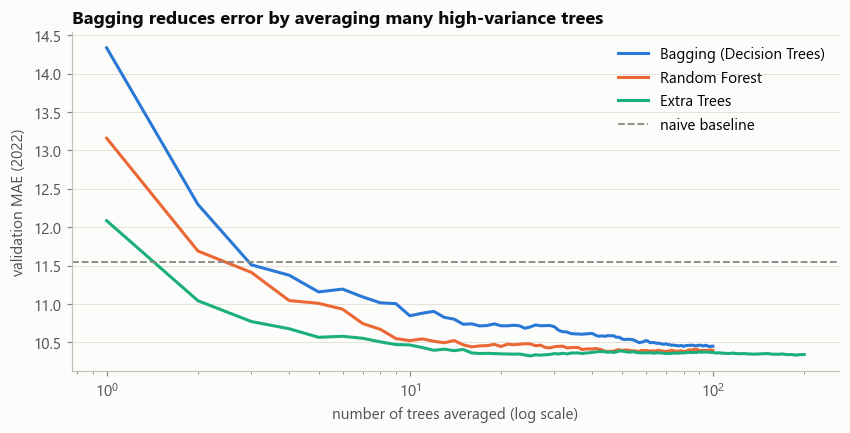

Bagging (Decision Trees)   1 tree: MAE 14.34 -> 100 trees: MAE 10.45  (27% lower)
Random Forest              1 tree: MAE 13.16 -> 100 trees: MAE 10.39  (21% lower)
Extra Trees                1 tree: MAE 12.08 -> 200 trees: MAE 10.34  (14% lower)


In [4]:
from sklearn.metrics import mean_absolute_error
def mae_vs_trees(pipe, X, y):
    inner = pipe.named_steps["model"].regressor_
    Xt = pipe.named_steps["prep"].transform(X)
    if hasattr(inner, "estimators_features_"):      # BaggingRegressor: each tree saw a feature subset
        per_tree = np.array([t.predict(Xt[:, f]) for t, f in zip(inner.estimators_, inner.estimators_features_)])
    else:
        per_tree = np.array([t.predict(Xt) for t in inner.estimators_])
    cum = np.cumsum(per_tree, axis=0) / np.arange(1, len(per_tree) + 1)[:, None]
    return np.array([mean_absolute_error(y, np.expm1(c)) for c in cum])

curves = {name: mae_vs_trees(fitted[name], va[feats], va.target) for name in BAGGING}
fig, ax = plt.subplots(figsize=(9, 4))
for i, (name, c) in enumerate(curves.items()):
    ax.plot(np.arange(1, len(c) + 1), c, color=viz.SERIES[i], label=name)
ax.axhline(E.load_results().set_index("model").loc[E.NAIVE_NAME, "val_MAE"], color=viz.MUTED, ls="--", lw=1.2,
           label="naive baseline")
ax.set_xscale("log"); ax.set_xlabel("number of trees averaged (log scale)"); ax.set_ylabel("validation MAE (2022)")
ax.set_title("Bagging reduces error by averaging many high-variance trees"); ax.legend()
viz.save(fig, "bagging_mae_vs_trees"); plt.show()
for name, c in curves.items():
    print(f"{name:26s} 1 tree: MAE {c[0]:.2f} -> {len(c)} trees: MAE {c[-1]:.2f}  ({100*(c[0]-c[-1])/c[0]:.0f}% lower)")

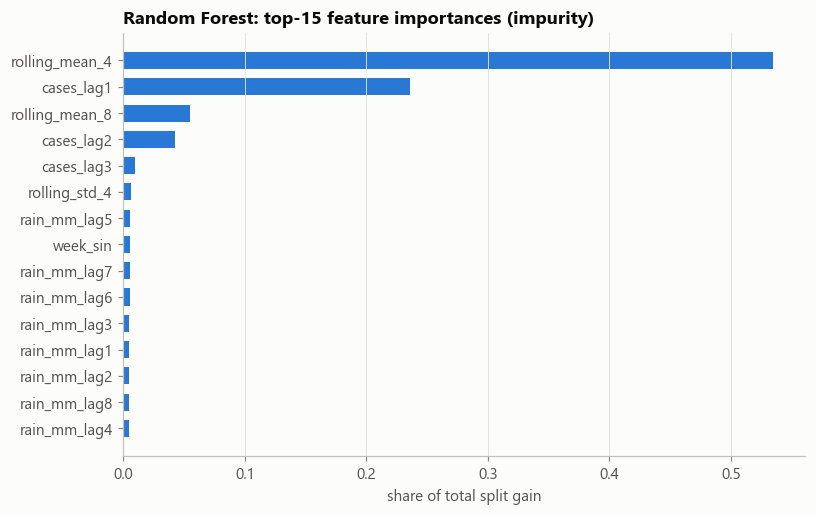

importance by feature group: {'cases (lags/rolling)': 0.887, 'weather': 0.096, 'calendar': 0.013, 'district': 0.003, 'missing flags': 0.0}


In [5]:
def importances(pipe, top=15):
    names = pipe.named_steps["prep"].get_feature_names_out()
    return pd.Series(pipe.named_steps["model"].regressor_.feature_importances_, index=names).sort_values(ascending=False).head(top)

imp = importances(fitted["Random Forest"])[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color=viz.SERIES[0], height=0.65)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Random Forest: top-15 feature importances (impurity)"); ax.set_xlabel("share of total split gain")
viz.save(fig, "fi_random_forest"); plt.show()
groups = importances(fitted["Random Forest"], top=None)
grp = groups.groupby(lambda n: "cases (lags/rolling)" if n.startswith(("cases", "rolling")) else
                     "weather" if n.startswith(("rain", "temp", "humid")) else
                     "district" if n.startswith("district") else "calendar" if n in ("week_sin", "week_cos", "year") else "missing flags").sum()
print("importance by feature group:", grp.sort_values(ascending=False).round(3).to_dict())

In [6]:
bag = E.results_table().query("family == 'Bagging'")
best = bag.sort_values("val_MAE").iloc[0]["model"]
print("best bagging model by validation MAE:", best)
M.save_model(fitted["Random Forest"], "random_forest.joblib")         # always kept: used by the hybrids
M.register("random_forest", "Random Forest", "random_forest.joblib", oob_r2_log=round(float(oob_r2), 4))
if best == "Random Forest":
    M.register("bagging_best", best, "random_forest.joblib")
else:
    fname = M.slug(best) + ".joblib"
    M.save_model(fitted[best], fname)
    M.register("bagging_best", best, fname)
print("search time (s):", {k: round(v) for k, v in search_time.items()})

best bagging model by validation MAE: Extra Trees


saved models/random_forest.joblib (15.4 MB)


saved models/extra_trees.joblib (15.6 MB)
search time (s): {'Bagging (Decision Trees)': 84, 'Random Forest': 111, 'Extra Trees': 49}
